# YOLO Car Detection, Tracking & Anomaly Demo — No Dataset Upload Needed

This Colab notebook automatically downloads a small **COCO128** object-detection subset through Ultralytics, fine-tunes a pretrained YOLO model, reports validation mAP, and creates a tracked video. It also includes a clearly labelled **synthetic anomaly demo** to show how suspicious samples can be flagged.

### Important limitations
- COCO128 is a small public subset for a coursework-sized pipeline; its mAP is a real measurement on this subset, not evidence of production-level performance.
- The anomaly examples below are **synthetically corrupted images**, not real damaged cars. This demonstrates the flagging workflow only. For real defect detection, use a labelled or normal/defective dataset.
- You do not need to upload a dataset. You will need to upload a video for the tracking section, unless you already have one available in Colab.

## 1. Set up Colab

In [1]:
!pip -q install -U ultralytics opencv-python-headless

import os, random, json, shutil, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Video
from ultralytics import YOLO
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("GPU available:", __import__("torch").cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.186
GPU available: True


## 2. Download and inspect the COCO128 subset

In [2]:
# Ultralytics downloads COCO128 automatically on first use.
from ultralytics.utils.downloads import download
from ultralytics.cfg import get_cfg
from ultralytics.data.utils import check_det_dataset

DATA_YAML = "coco128.yaml"
dataset_info = check_det_dataset(DATA_YAML)
print("Dataset YAML:", DATA_YAML)
print("Resolved dataset path:", dataset_info.get("path"))
print("Class names:", dataset_info.get("names"))
print("Train:", dataset_info.get("train"))
print("Val:", dataset_info.get("val"))


WARNING ⚠️ Dataset 'coco128.yaml' images not found, missing path '/content/datasets/coco128/images/train2017'
Unzipping /content/datasets/coco128.zip to /content/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 3.7Kfiles/s 0.1s
Dataset download success ✅ (0.5s), saved to /content/datasets

Dataset YAML: coco128.yaml
Resolved dataset path: /content/datasets/coco128
Class names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup'

### Visually inspect some labelled training images

This is the required label-quality sanity check. Boxes and class names are drawn from the dataset's YOLO labels. If boxes appear offset or class names are incorrect, investigate before training.

Training images found: 128


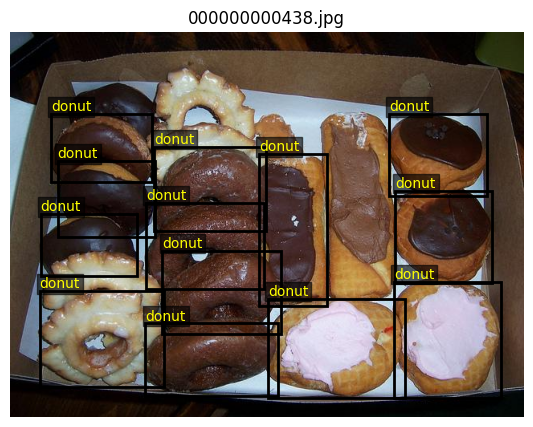

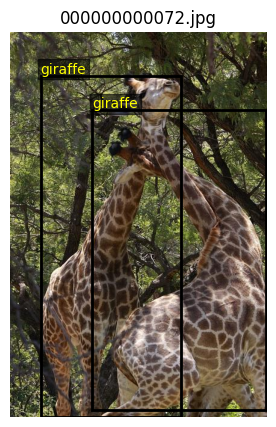

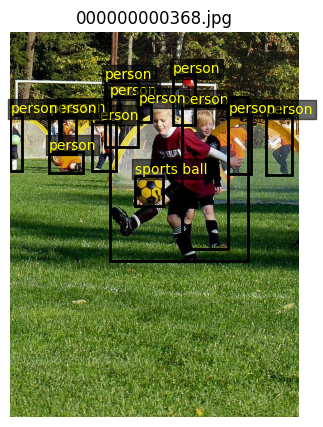

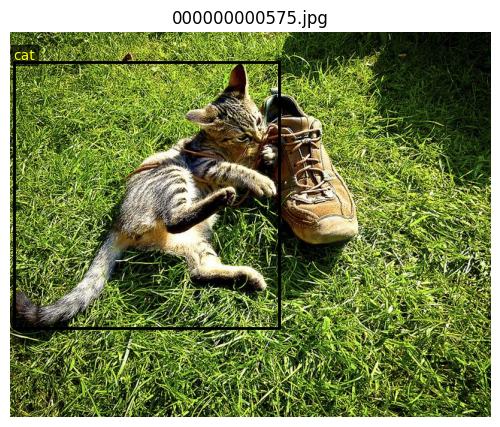

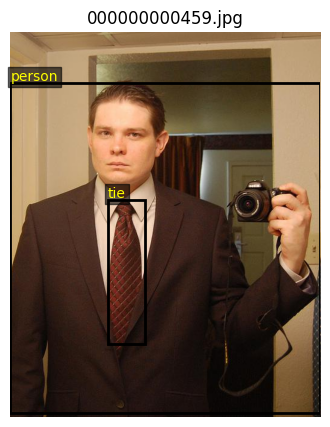

In [3]:
from pathlib import Path
from PIL import Image

root = Path(dataset_info["path"])
train_images = Path(dataset_info["train"])
if not train_images.is_absolute():
    train_images = root / train_images
label_dir = root / "labels" / "train"
img_files = sorted([p for p in train_images.glob("*") if p.suffix.lower() in {".jpg",".jpeg",".png"}])
print("Training images found:", len(img_files))

def label_for_image(p):
    # COCO128 standard layout: images/train2017 -> labels/train2017
    parts = list(p.parts)
    if "images" in parts:
        parts[parts.index("images")] = "labels"
    return Path(*parts).with_suffix(".txt")

names = dataset_info["names"]
for p in random.sample(img_files, min(5, len(img_files))):
    im = Image.open(p).convert("RGB")
    w, h = im.size
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(im)
    lab = label_for_image(p)
    if lab.exists():
        for line in lab.read_text().splitlines():
            vals = line.split()
            if len(vals) != 5:
                continue
            cls, xc, yc, bw, bh = map(float, vals)
            x1, y1 = (xc-bw/2)*w, (yc-bh/2)*h
            ax.add_patch(plt.Rectangle((x1,y1), bw*w, bh*h, fill=False, linewidth=2))
            ax.text(x1, max(0,y1-4), names[int(cls)], color="yellow",
                    bbox=dict(facecolor="black", alpha=.6, pad=2))
    ax.set_title(p.name)
    ax.axis("off")
    plt.show()

## 3. Fine-tune YOLO on the public subset

In [4]:
# Use pretrained weights, then fine-tune on COCO128.
# On a free Colab GPU this is a reasonable compact run; increase epochs for a stronger experiment.
MODEL_NAME = "yolov8n.pt"
EPOCHS = 25
IMG_SIZE = 640
BATCH = 16
PROJECT = "/content/car_yolo_outputs"
RUN_NAME = "coco128_car_detector"

model = YOLO(MODEL_NAME)
train_result = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    patience=8,
    pretrained=True,
    seed=42,
    project=PROJECT,
    name=RUN_NAME,
    plots=True,
    exist_ok=True
)
RUN_DIR = Path(PROJECT) / RUN_NAME
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
assert BEST_WEIGHTS.exists(), f"Checkpoint not found: {BEST_WEIGHTS}"
print("Best checkpoint:", BEST_WEIGHTS)

Ultralytics 8.4.186 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco128.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=coco128_car_detector, nbs=64, nms=None, opset=None, optimize=False, optimizer=

## 4. Evaluate and report mAP@50 and mAP@50–95

In [5]:
best_model = YOLO(str(BEST_WEIGHTS))
metrics = best_model.val(data=DATA_YAML, imgsz=IMG_SIZE, plots=True, project=PROJECT, name="validation", exist_ok=True)

report = {
    "dataset": "COCO128 (small public COCO subset)",
    "model": MODEL_NAME,
    "epochs_configured": EPOCHS,
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map)
}
display(pd.DataFrame([report]).round(4))
Path(PROJECT).mkdir(parents=True, exist_ok=True)
with open(Path(PROJECT)/"metrics.json", "w") as f:
    json.dump(report, f, indent=2)
print(f"mAP@50: {report['mAP50']:.4f}")
print(f"mAP@50–95: {report['mAP50_95']:.4f}")

Ultralytics 8.4.186 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2031.5±492.1 MB/s, size: 58.0 KB)
val: Scanning /content/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 44.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.7it/s 3.0s
                   all        128        929      0.832      0.681      0.794       0.61
                person         61        254      0.941      0.634      0.809       0.59
               bicycle          3          6          1      0.429      0.563      0.463
                   car         12         46      0.911      0.224      0.505       0.27
            motorcycle          4          5      0.805      0.832      0.962      0.855
              airplane          5    

,dataset,model,epochs_configured,precision,recall,mAP50,mAP50_95
0,COCO128 (small public COCO subset),yolov8n.pt,25,0.8315,0.6811,0.7941,0.61


mAP@50: 0.7941
mAP@50–95: 0.6100


## 5. Plot training metrics and save a short results write-up

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
20,21,63.0959,1.06249,1.01371,1.10207,0.83943,0.66652,0.78863,0.60253,0.95300,0.78943,1.03524,0.000025,0.000025,0.000025
21,22,65.7278,1.00517,0.95409,1.09680,0.85205,0.65506,0.79146,0.60499,0.95077,0.78691,1.03493,0.000020,0.000020,0.000020
22,23,68.3613,1.03194,0.96614,1.12217,0.85642,0.65274,0.79394,0.60930,0.94620,0.78400,1.03294,0.000015,0.000015,0.000015
23,24,70.9323,1.02156,0.93381,1.09902,0.83252,0.66926,0.79825,0.61112,0.94246,0.78092,1.03136,0.000011,0.000011,0.000011
24,25,73.4447,1.02189,0.94611,1.10179,0.80284,0.68608,0.79387,0.60894,0.94040,0.78118,1.03020,0.000006,0.000006,0.000006


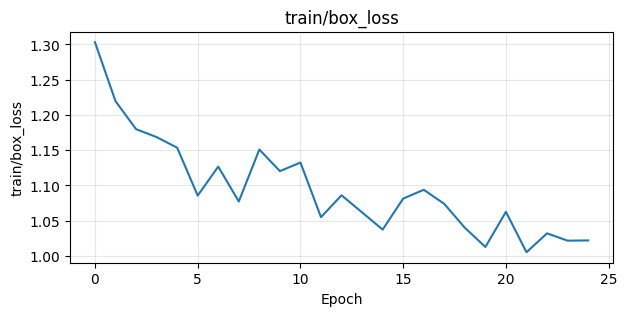

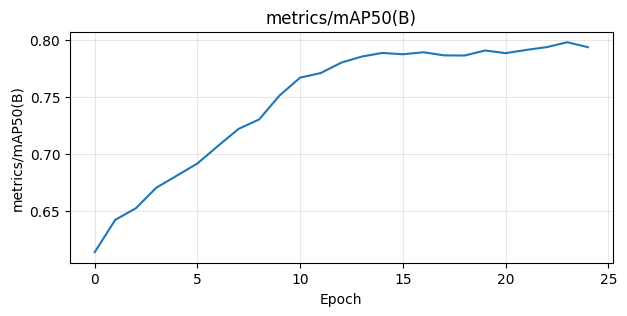

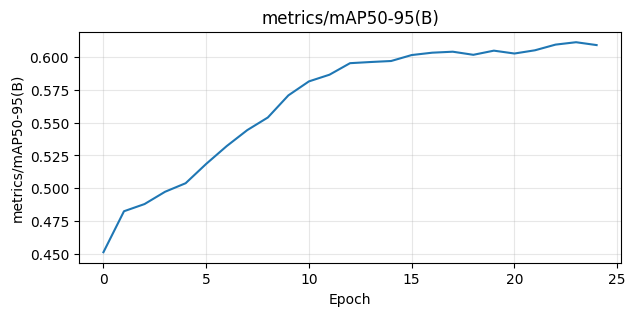

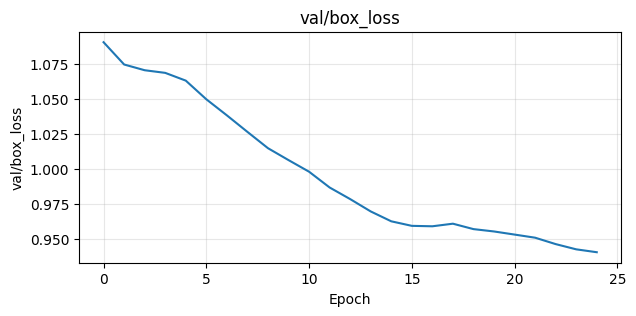

# YOLO Car Detection Results

- Dataset: COCO128 public subset
- Model initialized from: yolov8n.pt
- Configured epochs: 25
- Precision: 0.8315
- Recall: 0.6811
- mAP@50: 0.7941
- mAP@50–95: 0.6100

These are measurements from this run on the COCO128 validation split. The subset is small, so results should be interpreted as a coursework demonstration, not production performance.



In [6]:
results_csv = RUN_DIR / "results.csv"
if results_csv.exists():
    hist = pd.read_csv(results_csv)
    hist.columns = [c.strip() for c in hist.columns]
    display(hist.tail())
    cols = [c for c in hist.columns if any(k in c.lower() for k in ["map50", "map50-95", "train/box_loss", "val/box_loss"])]
    for c in cols:
        plt.figure(figsize=(7,3))
        plt.plot(hist[c])
        plt.title(c)
        plt.xlabel("Epoch")
        plt.ylabel(c)
        plt.grid(alpha=.3)
        plt.show()

summary = f'''# YOLO Car Detection Results

- Dataset: COCO128 public subset
- Model initialized from: {MODEL_NAME}
- Configured epochs: {EPOCHS}
- Precision: {report["precision"]:.4f}
- Recall: {report["recall"]:.4f}
- mAP@50: {report["mAP50"]:.4f}
- mAP@50–95: {report["mAP50_95"]:.4f}

These are measurements from this run on the COCO128 validation split. The subset is small, so results should be interpreted as a coursework demonstration, not production performance.
'''
(Path(PROJECT)/"results_summary.md").write_text(summary)
print(summary)

## 6. Create a tracked output video

Upload any short road/traffic video (`.mp4`, `.mov`, `.avi`, `.mkv`). The trained detector is based on COCO classes, including car, bus, truck, person and bicycle. ByteTrack associates detections across frames and overlays IDs. Track IDs may change after long occlusions or when objects leave/re-enter.

In [7]:
from google.colab import files
uploaded = files.upload()
video_files = [Path("/content")/n for n in uploaded if Path(n).suffix.lower() in {".mp4",".mov",".avi",".mkv"}]
assert video_files, "Please upload a video file."
VIDEO_PATH = video_files[0]

track_results = best_model.track(
    source=str(VIDEO_PATH),
    tracker="bytetrack.yaml",
    persist=True,
    conf=0.25,
    save=True,
    project=PROJECT,
    name="tracked_video",
    exist_ok=True,
    verbose=False
)
TRACK_DIR = Path(PROJECT)/"tracked_video"
output_videos = [p for p in TRACK_DIR.rglob("*") if p.suffix.lower() in {".mp4",".avi",".mov",".mkv"}]
print("Tracked video files:", output_videos)
if output_videos:
    print("Previewing:", output_videos[0])
    display(Video(str(output_videos[0]), embed=True))

Saving istockphoto-866517852-640_adpp_is.mp4 to istockphoto-866517852-640_adpp_is.mp4
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 202ms
Prepared 1 package in 57ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to 

## 7. Synthetic anomaly-flagging demo

Because no defect dataset was supplied, this section creates a few **synthetically altered images** from validation images (for example, artificial patch/contrast corruption) and flags samples based on how much they differ from the source. This proves the workflow can produce flags and preview examples; it does **not** validate real car-damage detection.

In [8]:
import cv2

ANOMALY_DIR = Path(PROJECT)/"anomaly_demo"
ANOMALY_DIR.mkdir(parents=True, exist_ok=True)

# Select validation images and create synthetic examples with an obvious artificial patch.
val_images = Path(dataset_info["val"])
if not val_images.is_absolute():
    val_images = root / val_images
val_files = sorted([p for p in val_images.glob("*") if p.suffix.lower() in {".jpg",".jpeg",".png"}])
chosen = random.sample(val_files, min(8, len(val_files)))
rows = []

for i, p in enumerate(chosen):
    original = cv2.imread(str(p))
    if original is None:
        continue
    h, w = original.shape[:2]
    synthetic = original.copy()
    # Synthetic corruption: conspicuous rectangular patch. This is deliberately a toy example.
    x1, y1 = int(w*0.55), int(h*0.55)
    x2, y2 = min(w-1, x1+max(12,int(w*0.18))), min(h-1, y1+max(12,int(h*0.18)))
    cv2.rectangle(synthetic, (x1,y1), (x2,y2), (0,0,255), thickness=-1)
    cv2.putText(synthetic, "SYNTHETIC", (max(0,x1-5), max(20,y1-8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,0,255), 2)
    out_path = ANOMALY_DIR/f"synthetic_anomaly_{i:02d}.jpg"
    cv2.imwrite(str(out_path), synthetic)

    # Simple image-difference score against its source, not a learned defect score.
    diff = cv2.absdiff(original, synthetic)
    score = float(diff.mean())
    rows.append({"source": str(p), "synthetic_sample": str(out_path),
                 "difference_score": score, "flag_for_review": score > 1.0})

anomaly_df = pd.DataFrame(rows).sort_values("difference_score", ascending=False)
anomaly_df.to_csv(Path(PROJECT)/"synthetic_anomaly_flags.csv", index=False)
display(anomaly_df)
print("Flagged samples:", int(anomaly_df["flag_for_review"].sum()), "/", len(anomaly_df))

,source,synthetic_sample,difference_score,flag_for_review
0,/content/datasets/coco128/images/train2017/000...,/content/car_yolo_outputs/anomaly_demo/synthet...,4.858159,True
3,/content/datasets/coco128/images/train2017/000...,/content/car_yolo_outputs/anomaly_demo/synthet...,3.784417,True
7,/content/datasets/coco128/images/train2017/000...,/content/car_yolo_outputs/anomaly_demo/synthet...,3.642795,True
6,/content/datasets/coco128/images/train2017/000...,/content/car_yolo_outputs/anomaly_demo/synthet...,3.352979,True
2,/content/datasets/coco128/images/train2017/000...,/content/car_yolo_outputs/anomaly_demo/synthet...,3.317950,True
5,/content/datasets/coco128/images/train2017/000...,/content/car_yolo_outputs/anomaly_demo/synthet...,3.259900,True
4,/content/datasets/coco128/images/train2017/000...,/content/car_yolo_outputs/anomaly_demo/synthet...,3.101645,True
1,/content/datasets/coco128/images/train2017/000...,/content/car_yolo_outputs/anomaly_demo/synthet...,3.096103,True


Flagged samples: 8 / 8


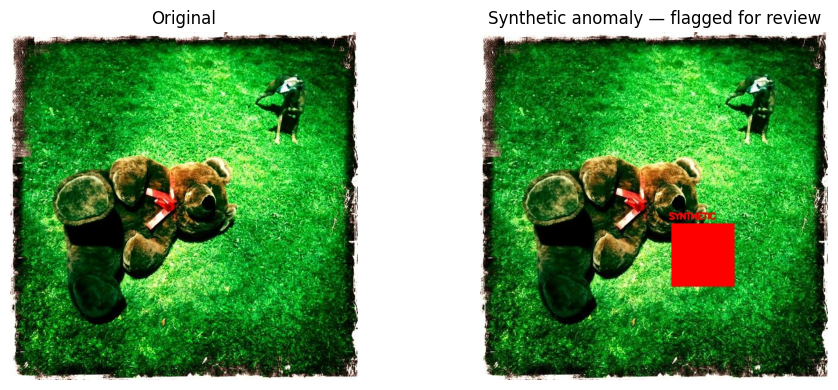

In [10]:
# Visual comparison of one original image and its synthetic counterpart
if len(rows):
    row = rows[0]
    original = cv2.cvtColor(cv2.imread(row["source"]), cv2.COLOR_BGR2RGB)
    altered = cv2.cvtColor(cv2.imread(row["synthetic_sample"]), cv2.COLOR_BGR2RGB)
    fig, axes = plt.subplots(1,2,figsize=(10,4))
    axes[0].imshow(original); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(altered); axes[1].set_title("Synthetic anomaly — flagged for review"); axes[1].axis("off")
    plt.tight_layout()
    plt.show()

## 8. Package all outputs for submission

In [11]:
zip_path = Path("/content/car_yolo_deliverables.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in Path(PROJECT).rglob("*"):
        if p.is_file() and p != zip_path:
            z.write(p, arcname=str(Path("car_yolo_outputs")/p.relative_to(Path(PROJECT))))
    if BEST_WEIGHTS.exists():
        z.write(BEST_WEIGHTS, arcname="weights/best.pt")
print("Created:", zip_path)
files.download(str(zip_path))

Created: /content/car_yolo_deliverables.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Submission checklist

- [ ] Label overlays visually inspected before training
- [ ] YOLO fine-tuned from pretrained weights
- [ ] Real validation mAP@50 and mAP@50–95 saved
- [ ] Training curves and `results_summary.md` saved
- [ ] Tracked video played and track IDs checked across frames
- [ ] Synthetic anomaly flags and preview saved
- [ ] ZIP downloaded and included in your submission

**Be transparent in the report:** the detector is trained/evaluated on a small public COCO subset; the anomaly demo uses synthetic corruption because no real defect dataset was provided.